# Bowl transducer: source velocity for a target acoustic power

This notebook uses OptimUS to find the uniform normal surface velocity $u$ that a focused bowl transducer needs to radiate a given acoustic power $P_\mathrm{target}$.

In a linear, lossless medium the pressure scales with $u$ and the radiated power with $u^2$. So it is enough to compute the power $P_1$ radiated at $u = 1$ m/s, and then

$$u = \sqrt{P_\mathrm{target} / P_1}.$$

$P_1$ is estimated in three independent ways:

1. **Numerical, plane:** the pressure field is integrated over a plane in front of the bowl.
2. **Numerical, hemisphere:** the pressure field is integrated over a hemisphere enclosing the bowl.
3. **Analytical:** the O'Neil focal-plane solution, as used by Civale et al. (2018).

To check the results, the notebook compares the focal-plane pressure profiles, verifies the radiated power through the focal plane, and plots the pressure field.



In [1]:
import sys
sys.path.append('..')

import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate, special

import optimus
from optimus.source.transducers import transducer_field

# Simpson's rule: `simpson` in recent SciPy, `simps` in older versions.
simpson = getattr(integrate, 'simpson', None) or integrate.simps

In [2]:
%matplotlib inline
plt.rcParams.update({'font.size': 13, 'figure.facecolor': 'white'})

## Parameters

All quantities are in SI units. The medium is water without attenuation, because the power must be conserved for the surface integrals to be independent of the integration surface.

| Parameter | Meaning |
|---|---|
| `target_power` | Desired radiated acoustic power (W) |
| `frequency` | Driving frequency (Hz) |
| `radius_outer` | Outer (aperture) radius of the bowl, $a$ (m) |
| `radius_inner` | Radius of a central hole, 0 for a solid bowl (m) |
| `roc` | Radius of curvature, which is also the geometric focal distance, $R$ (m) |
| `source_axis` | Direction of propagation; the bowl apex is at the origin |
| `points_per_wavelength` | Point-source density used by OptimUS to discretise the bowl |
| `points_per_wavelength_field` | Point density used to discretise the integration plane or hemisphere |

In [3]:
target_power = 2          # W, acoustic power

# Transducer
frequency = 0.2e6             # Hz
radius_outer = 32e-3           # m
radius_inner = 0.0             # m
roc = 2 * radius_outer         # m  (f-number = roc / (2 * radius_outer))
source_axis = (1, 0, 0)
points_per_wavelength = 12

# Propagation medium
density = 1000.0               # kg/m^3
speed_of_sound = 1500.0        # m/s

## Source and medium

The bowl is created with a unit velocity. Changing `source.velocity` later rescales the field without rebuilding the source.

The helper `normal_intensity` returns the complex pressure $p$ and the time-averaged intensity normal to the evaluation surface,

$$I_n = \tfrac{1}{2}\,\mathrm{Re}\left(p\,u_n^*\right), \qquad u_n = \frac{\partial p/\partial n}{i\omega\rho}.$$

In [4]:
medium = optimus.material.create_material(name='water-no-attenuation',
                                          density=density,
                                          speed_of_sound=speed_of_sound)
medium.print()

source = optimus.source.create_bowl(frequency, outer_radius=radius_outer, radius_of_curvature=roc,
                                    inner_radius=radius_inner, source_axis=source_axis, velocity=1.0,
                                    number_of_point_sources_per_wavelength=points_per_wavelength)

omega = 2 * np.pi * frequency
k = np.real(medium.compute_wavenumber(frequency))
wavelength = 2 * np.pi / k
rho_c = density * speed_of_sound
bowl_depth = roc - np.sqrt(roc**2 - radius_outer**2)
print('Wavelength: {:.3f} mm,  f-number: {:.2f},  bowl depth: {:.2f} mm'.format(
    wavelength * 1e3, roc / (2 * radius_outer), bowl_depth * 1e3))


def normal_intensity(points, normals, velocity=1.0):
    # Pressure and time-averaged normal intensity at `points` for a given surface velocity.
    source.velocity = np.atleast_1d(complex(velocity))
    field = transducer_field(source, medium, points, normals=normals)
    p = field.pressure
    u_n = field.normal_pressure_gradient / (1j * omega * density)
    return p, 0.5 * np.real(p * np.conj(u_n))


def power_through_plane(x_plane, r_max, n_points):
    # Power at unit velocity through the plane x = x_plane, within radius r_max (axisymmetric).
    r = np.linspace(0, r_max, n_points)
    points = np.vstack((x_plane * np.ones_like(r), np.zeros_like(r), r))
    normals = np.zeros_like(points)
    normals[0] = 1.0
    _, I_x = normal_intensity(points, normals)
    return 2 * np.pi * simpson(I_x * r, x=r), r, I_x

                 name  density  speed_of_sound  attenuation_coeff_a  attenuation_pow_b
 water-no-attenuation   1000.0          1500.0                  0.0                0.0
Wavelength: 7.500 mm,  f-number: 1.00,  bowl depth: 8.57 mm


## Method 1: numerical, plane integration

The power through a plane $x = x_p$ perpendicular to the beam axis is

$$P = \int I_x\,dA = 2\pi\int_0^{r_\mathrm{max}} I_x(r)\,r\,dr.$$

The field is axisymmetric, so $I_x$ is only needed along one radial line. The plane lies between the bowl and the focus ($x_p = 0.7R$) and extends to $r_\mathrm{max} = 15a$ so that it captures nearly all of the forward-radiated power. The line is sampled at 12 points per wavelength.

Power at 1 m/s: 2602.74 W  ->  velocity for 2 W: 0.02772 m/s


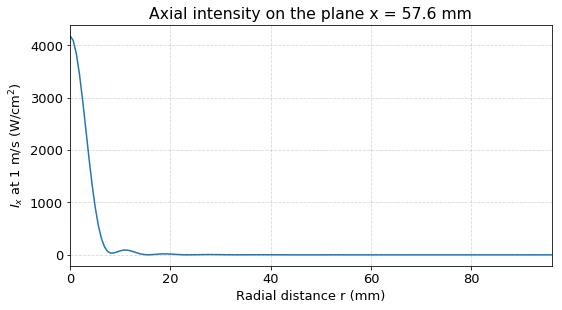

In [5]:
x_plane = 0.9 * roc
r_max = 15 * radius_outer
points_per_wavelength_field = 12
n_plane = int(r_max / wavelength * points_per_wavelength_field)

P1_plane, r_plane, I_plane = power_through_plane(x_plane, r_max, n_plane)
u_plane = np.sqrt(target_power / P1_plane)
print('Power at 1 m/s: {:.2f} W  ->  velocity for {} W: {:.5f} m/s'.format(P1_plane, target_power, u_plane))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(r_plane * 1e3, I_plane * 1e-4)
ax.set_xlim(0, 3 * radius_outer * 1e3)
ax.set_xlabel('Radial distance r (mm)')
ax.set_ylabel('$I_x$ at 1 m/s (W/cm$^2$)')
ax.set_title('Axial intensity on the plane x = {:.1f} mm'.format(x_plane * 1e3))
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Method 2: numerical, hemisphere integration

The power through a hemisphere of radius $R_h$, centred on the bowl apex and enclosing the bowl, is

$$P = 2\pi R_h^2\int_0^{\pi/2} I_n(\theta)\,\sin\theta\,d\theta,$$

where $\theta$ is the angle from the beam axis and $I_n$ is the radial (outward) intensity. $R_h$ is set 10% larger than the distance from the apex to the bowl rim, $\sqrt{a^2 + h^2}$, where $h$ is the bowl depth.

In [6]:
R_hemisphere = 1.1 * np.sqrt(radius_outer**2 + bowl_depth**2)
theta = np.linspace(0, np.pi / 2, 2001)
points_hemi = R_hemisphere * np.vstack((np.cos(theta), np.sin(theta), np.zeros_like(theta)))
normals_hemi = points_hemi / R_hemisphere

_, I_hemi = normal_intensity(points_hemi, normals_hemi)
P1_hemisphere = 2 * np.pi * R_hemisphere**2 * simpson(I_hemi * np.sin(theta), x=theta)
u_hemisphere = np.sqrt(target_power / P1_hemisphere)
print('Hemisphere radius: {:.1f} mm'.format(R_hemisphere * 1e3))
print('Power at 1 m/s: {:.2f} W  ->  velocity for {} W: {:.5f} m/s'.format(P1_hemisphere, target_power, u_hemisphere))

Hemisphere radius: 36.4 mm
Power at 1 m/s: 2740.80 W  ->  velocity for 2 W: 0.02701 m/s


## Method 3: analytical solution (O'Neil / Civale et al. 2018)

The velocity potential in the focal plane of a solid bowl, with aperture radius $a$, radius of curvature $R$, surface area $S$ and surface velocity $u$, is (Civale et al. 2018, Eqs. 1–4, after O'Neil 1949)

$$\psi = u\,S\,\frac{e^{-ikR}}{2\pi R}\,F(z),\qquad F(z) = \frac{2}{z}\sum_{n=0}^{\infty}(-1)^n\,T^{2n}\,J_{2n+1}(z),$$

$$z \approx k a \sin\theta,\qquad T = \tan(\alpha/2),\qquad \sin\alpha = a/R,$$

where $\theta$ is the angle between the bowl axis and the line from the centre of curvature to the field point. For a bowl with a central hole of radius $r_1$, the solid bowl of radius $r_1$ is subtracted from that of radius $r_2$ (Eq. 7):

$$\psi = \frac{e^{-ikR}}{2\pi R}\,u\,\big(S_{r_2}F_{r_2} - S_{r_1}F_{r_1}\big).$$

The pressure amplitude is $|p| = \rho c\,k\,|\psi|$. All of the radiated power crosses the focal plane, so the power is $P = 2\pi\int |p|^2/(2\rho c)\,r\,dr$. Following the paper, the series is truncated after 11 terms and the focal plane at $\theta = 0.6$ rad. The approximation is valid roughly for f-numbers above 0.9 and $\theta < 30^\circ$; it is less accurate for more strongly focused bowls.

**Reference:** J. Civale, I. Rivens, A. Shaw, G. ter Haar, *Focused ultrasound transducer spatial peak intensity estimation: a comparison of methods*, Phys. Med. Biol. 63, 055015 (2018). [doi:10.1088/1361-6560/aaaf01](https://doi.org/10.1088/1361-6560/aaaf01)

In [7]:
def solid_bowl_area(a, roc):
    # Surface area of a solid spherical bowl with aperture radius a.
    return 2 * np.pi * roc * (roc - np.sqrt(roc**2 - a**2))


def focusing_function(r, a, roc, k, n_terms=11):
    # O'Neil focusing function F of a solid bowl in the focal plane (Civale Eqs. 2-4).
    T = np.tan(np.arcsin(a / roc) / 2)
    z = k * a * np.sin(np.arctan(r / roc))
    series = sum((-1)**n * T**(2 * n) * special.jv(2 * n + 1, z) for n in range(n_terms))
    z_safe = np.where(z > 1e-12, z, 1.0)
    return np.where(z > 1e-12, 2 * series / z_safe, 1.0)


def bowl_focal_plane_pressure(r, velocity=1.0):
    # Pressure amplitude in the focal plane at radial distance r (Civale Eqs. 1-4 and 7).
    psi = velocity / (2 * np.pi * roc) * (
        solid_bowl_area(radius_outer, roc) * focusing_function(r, radius_outer, roc, k)
        - solid_bowl_area(radius_inner, roc) * focusing_function(r, radius_inner, roc, k))
    return rho_c * k * np.abs(psi)


r_ana = np.linspace(0, roc * np.tan(0.6), 4000)
P1_analytical = 2 * np.pi * simpson(bowl_focal_plane_pressure(r_ana)**2 / (2 * rho_c) * r_ana, x=r_ana)
u_analytical = np.sqrt(target_power / P1_analytical)
print('Power at 1 m/s: {:.2f} W  ->  velocity for {} W: {:.5f} m/s'.format(P1_analytical, target_power, u_analytical))

Power at 1 m/s: 2745.67 W  ->  velocity for 2 W: 0.02699 m/s


## Comparison of the velocity estimates

The difference is relative to the analytical solution.

In [8]:
results = [('Analytical', P1_analytical, u_analytical),
           ('Numerical - plane', P1_plane, u_plane),
           ('Numerical - hemisphere', P1_hemisphere, u_hemisphere)]

print('Velocity required for {} W of acoustic power:\n'.format(target_power))
print('{:<24}{:>16}{:>16}{:>14}'.format('Method', 'P at 1 m/s (W)', 'u (m/s)', 'diff. u (%)'))
for name, P1, u in results:
    print('{:<24}{:>16.2f}{:>16.5f}{:>14.2f}'.format(name, P1, u, 100 * (u / u_analytical - 1)))

Velocity required for 2 W of acoustic power:

Method                    P at 1 m/s (W)         u (m/s)   diff. u (%)
Analytical                       2745.67         0.02699          0.00
Numerical - plane                2602.74         0.02772          2.71
Numerical - hemisphere           2740.80         0.02701          0.09


## Validation: focal-plane pressure

The pressure on a radial line in the focal plane ($x = R$) is computed with OptimUS at unit velocity and scaled by each numerical velocity estimate. It is then compared with the analytical profile at the analytical velocity. The table lists the peak focal pressure, the corresponding spatial-peak intensity $I_\mathrm{SP} = p^2/(2\rho c)$, and the −6 dB (FWHM) width of the pressure profile.

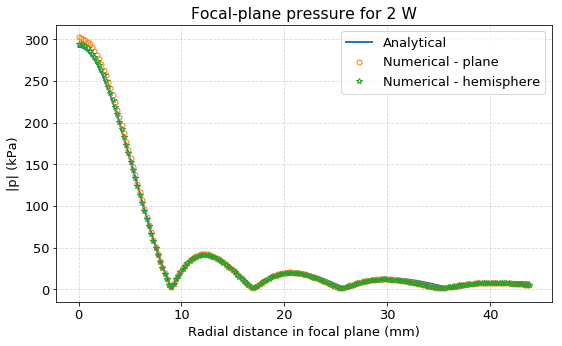

Method                     p_max (kPa)   I_SP (W/cm^2)   FWHM (mm)
Analytical                       290.8           2.819      10.472
Numerical - plane                302.2           3.044      10.385
Numerical - hemisphere           294.5           2.891      10.385


In [9]:
def fwhm(r, p):
    # Full width at half maximum of a radial pressure profile p(r) that peaks at r = 0.
    below = np.where(p < 0.5 * p.max())[0]
    if len(below) == 0:
        return np.nan
    i = below[0]
    r_half = np.interp(0.5 * p.max(), [p[i], p[i - 1]], [r[i], r[i - 1]])
    return 2 * r_half


r_focal = np.linspace(0, roc * np.tan(0.6), 200)
points_focal = np.vstack((roc * np.ones_like(r_focal), r_focal, np.zeros_like(r_focal)))
source.velocity = np.ones(1, dtype=complex)
p_focal_unit = np.abs(transducer_field(source, medium, points_focal).pressure)

profiles = [('Analytical', r_ana, bowl_focal_plane_pressure(r_ana, u_analytical)),
            ('Numerical - plane', r_focal, p_focal_unit * u_plane),
            ('Numerical - hemisphere', r_focal, p_focal_unit * u_hemisphere)]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(r_ana * 1e3, profiles[0][2] / 1e3, '-', lw=2, label=profiles[0][0])
ax.plot(r_focal * 1e3, profiles[1][2] / 1e3, 'o', mfc='none', ms=5, label=profiles[1][0])
ax.plot(r_focal * 1e3, profiles[2][2] / 1e3, '*', mfc='none', ms=6, label=profiles[2][0])
ax.set_xlabel('Radial distance in focal plane (mm)')
ax.set_ylabel('|p| (kPa)')
ax.set_title('Focal-plane pressure for {} W'.format(target_power))
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print('{:<24}{:>14}{:>16}{:>12}'.format('Method', 'p_max (kPa)', 'I_SP (W/cm^2)', 'FWHM (mm)'))
for name, r, p in profiles:
    print('{:<24}{:>14.1f}{:>16.3f}{:>12.3f}'.format(
        name, p[0] / 1e3, p[0]**2 / (2 * rho_c) * 1e-4, fwhm(r, p) * 1e3))

## Verification: power through the focal plane

As an independent check, the OptimUS intensity is integrated over the focal plane ($x = R$, out to $r = 15a$), a different surface from the ones used to estimate the velocities. Because the medium is lossless, each estimated velocity should give a power close to the target.

In [10]:
P1_focal, _, _ = power_through_plane(roc, r_max, n_plane)
print('Power through the focal plane at 1 m/s: {:.2f} W\n'.format(P1_focal))
print('{:<24}{:>14}{:>18}'.format('Velocity from', 'P (W)', 'diff. target (%)'))
for name, _, u in results:
    P = P1_focal * u**2
    print('{:<24}{:>14.4f}{:>18.2f}'.format(name, P, 100 * (P / target_power - 1)))

Power through the focal plane at 1 m/s: 2601.42 W

Velocity from                    P (W)  diff. target (%)
Analytical                      1.8949             -5.25
Numerical - plane               1.9990             -0.05
Numerical - hemisphere          1.8983             -5.09


## Pressure field at the estimated velocity

The pressure amplitude in the $xy$-plane, for the velocity from the method selected in `selected_method`.

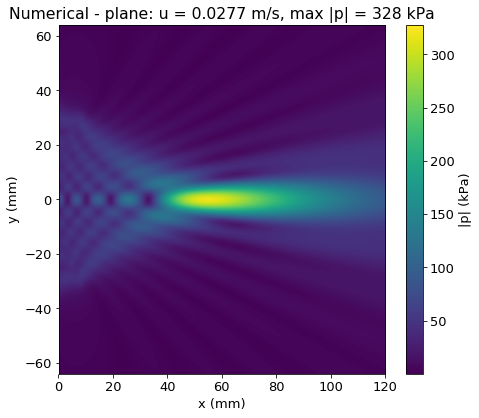

In [11]:
selected_method = 'Numerical - plane'
source_velocity = dict((name, u) for name, _, u in results)[selected_method]
source.velocity = np.atleast_1d(complex(source_velocity))

grid_resolution = (121, 81)
grid_lims = (1e-4, 0.12, -2 * radius_outer, 2 * radius_outer)   # (x_min, x_max, y_min, y_max)
points_map, _ = optimus.utils.mesh.create_grid_points(resolution=grid_resolution, plane_axes=(0, 1),
                                                      plane_offset=0, bounding_box=grid_lims, mode='numpy')
p_map = np.abs(transducer_field(source, medium, points_map).pressure).reshape(grid_resolution).T

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(p_map / 1e3, cmap='viridis', origin='lower', interpolation='bicubic',
               extent=[1e3 * grid_lims[0], 1e3 * grid_lims[1], 1e3 * grid_lims[2], 1e3 * grid_lims[3]])
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('|p| (kPa)')
ax.set_xlabel('x (mm)')
ax.set_ylabel('y (mm)')
ax.set_title('{}: u = {:.4f} m/s, max |p| = {:.0f} kPa'.format(selected_method, source_velocity, p_map.max() / 1e3))
plt.tight_layout()
plt.show()